In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

In [3]:
df = pd.read_csv(r"C:\Users\Dell\Desktop\Adam\Experiments\Etsy-checkout-abtest\data\processed\Redesign_checkout.csv")

In [5]:
df.head()

,user_id,variant,device,visitor_type,converted,user_revenue,order_count
0,1,treatment,tablet,new,0,0.0,0
1,2,treatment,desktop,new,0,0.0,0
2,3,control,desktop,new,0,0.0,0
3,4,control,mobile,returning,0,0.0,0
4,5,control,mobile,returning,0,0.0,0


In [13]:
# Number of Observations and unique Users
print("Rows" , len(df))
print("Unique Users" , df['user_id'].nunique())

# Checking Duplicates
print("Duplicate User_IDs" , df['user_id'].duplicated().sum())

conv_df = df.groupby("variant").agg(
    total_conversions = ('converted' , 'sum'),
    total_users = ('converted' , 'count'),
    conversion_rate = ('converted' , 'mean'),
    std_error = ('converted' , lambda x : x.sem())
).reset_index()
print(conv_df)


Rows 30716
Unique Users 30716
Duplicate User_IDs 0
     variant  total_conversions  total_users  conversion_rate  std_error
0    control               1114        15339         0.072625   0.002095
1  treatment               1189        15377         0.077323   0.002154


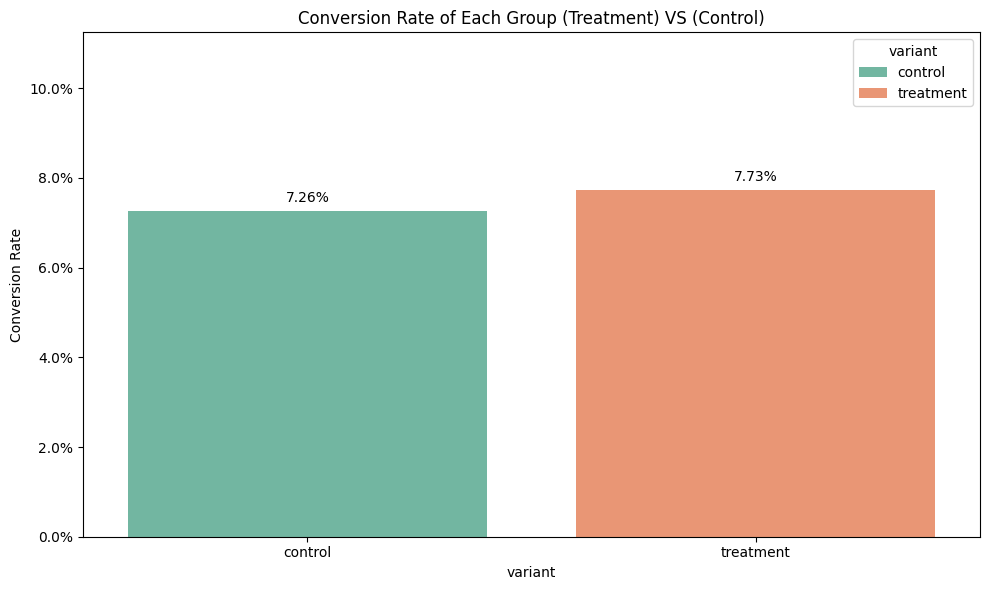

In [ ]:
fig , ax = plt.subplots(figsize = (10,6))
sns.barplot(
    data= conv_df,
    x= 'variant',
    y= 'conversion_rate',
    palette= 'Set2',
    hue= 'variant',
    errorbar= None,
    legend= True,
    ax=ax)

# Format the y_axis to be in Percentages
ax.yaxis.set_major_formatter(PercentFormatter(1))

# Add Percentage labels above each bar
for container in ax.containers:
    labels = [f"{bar.get_height():.2%}" for bar in container]
    ax.bar_label(
        container,
        labels,
        padding= 4
    )

ax.set_title("Conversion Rate of Each Group (Treatment) VS (Control)")
ax.set_xlabel("variant")
ax.set_ylabel("Conversion Rate")
ax.set_ylim(0 , conv_df["conversion_rate"].mean() * 1.5)
plt.tight_layout()
plt.show()

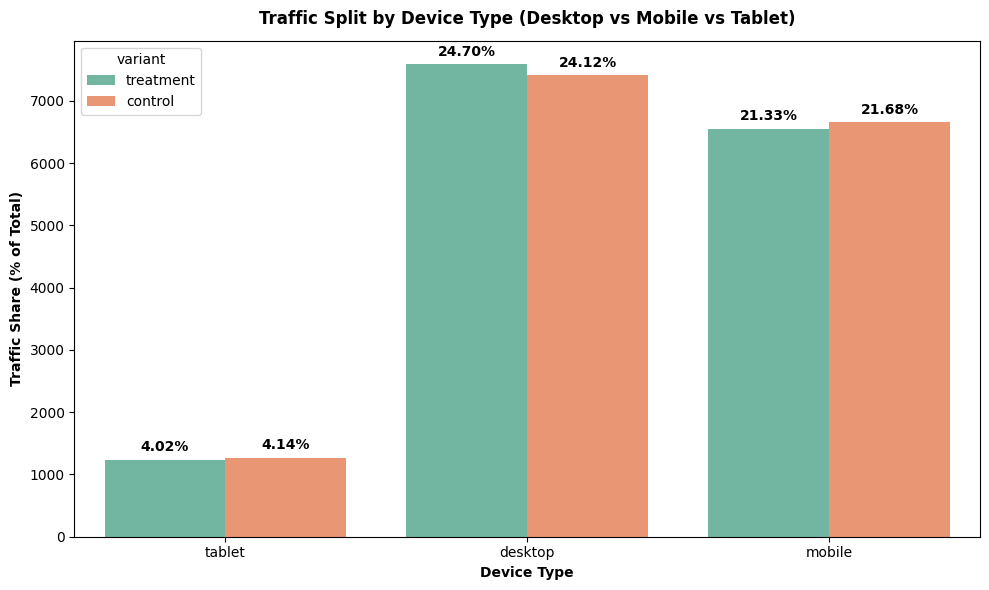

In [22]:
# Traffic Split by Device
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(
    data=df, x="device", palette="Set2", hue="variant", legend=True, ax=ax
)

# Compute percentage relative to total traffic
total_users = len(df)
for container in ax.containers:
    labels = [
        f"{bar.get_height() / total_users:.2%}"
        if bar.get_height() > 0
        else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=4, fontweight="bold")

ax.set_title(
    "Traffic Split by Device Type (Desktop vs Mobile vs Tablet)",
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Device Type", fontweight="bold")
ax.set_ylabel("Traffic Share (% of Total)", fontweight="bold")

plt.tight_layout()
plt.show()

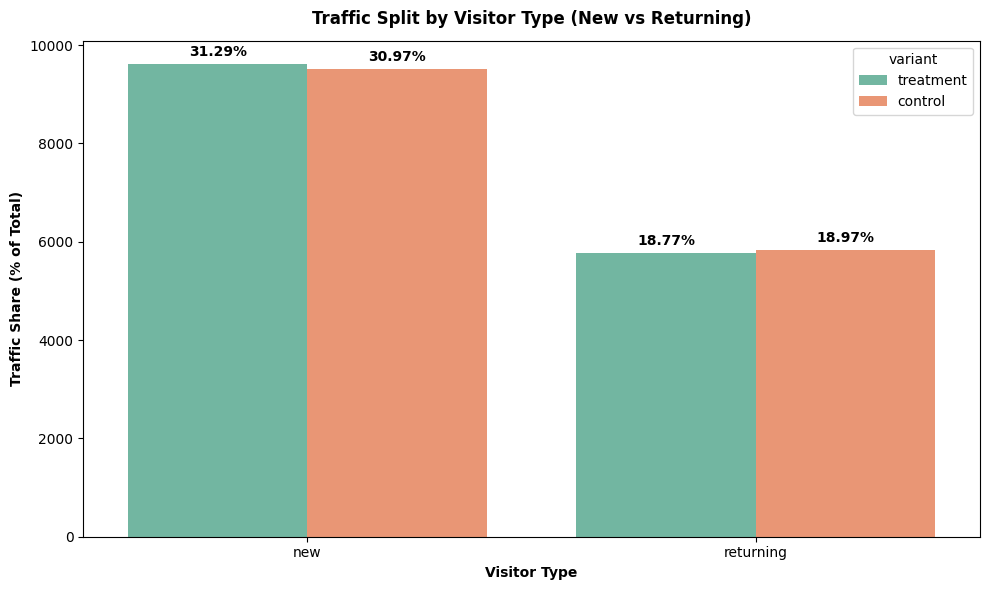

In [23]:
# Traffic Split by Visitor Type
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(
    data=df, x="visitor_type", palette="Set2", hue="variant", legend=True, ax=ax
)

total_users = len(df)
for container in ax.containers:
    labels = [
        f"{bar.get_height() / total_users:.2%}"
        if bar.get_height() > 0
        else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=4, fontweight="bold")

ax.set_title(
    "Traffic Split by Visitor Type (New vs Returning)",
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Visitor Type", fontweight="bold")
ax.set_ylabel("Traffic Share (% of Total)", fontweight="bold")

plt.tight_layout()
plt.show()

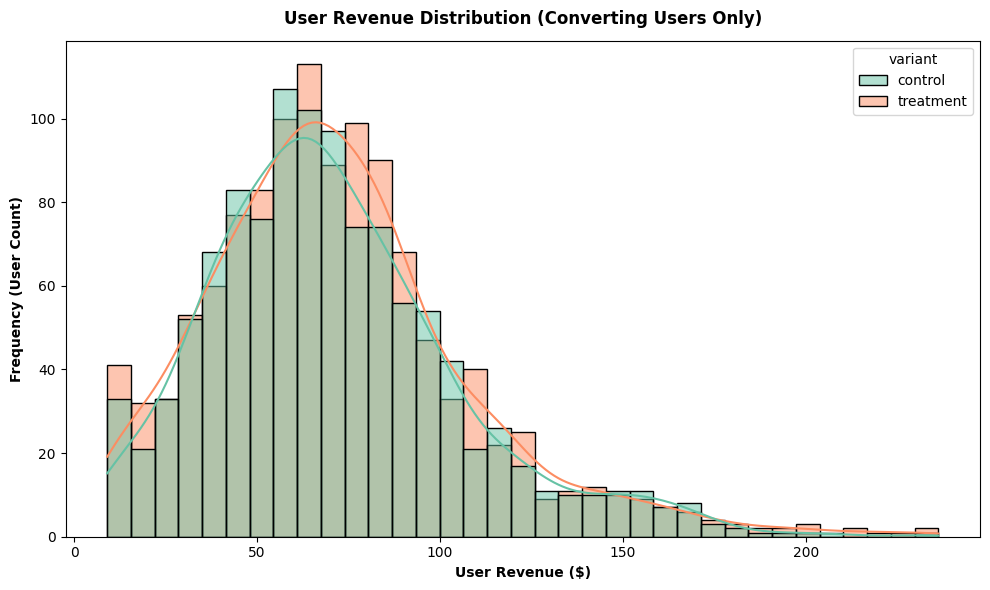

In [24]:
# Revenue Distribution for Converting Users
fig, ax = plt.subplots(figsize=(10, 6))
converting_df = df[df["converted"] == 1]

sns.histplot(
    data=converting_df,
    x="user_revenue",
    hue="variant",
    palette="Set2",
    bins=35,
    kde=True,
    ax=ax,
)

ax.set_title(
    "User Revenue Distribution (Converting Users Only)",
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("User Revenue ($)", fontweight="bold")
ax.set_ylabel("Frequency (User Count)", fontweight="bold")

plt.tight_layout()
plt.show()

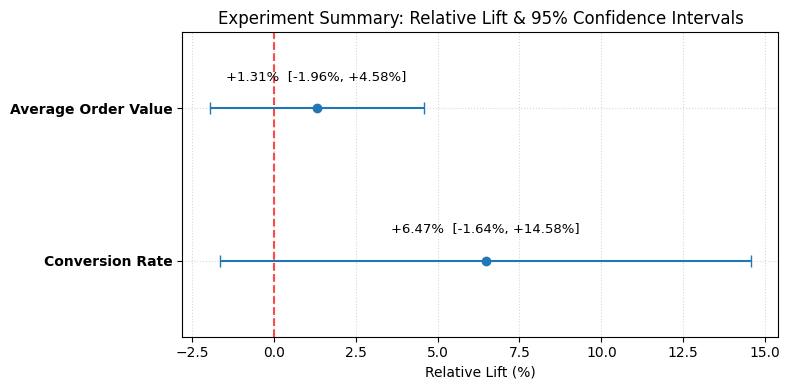

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Summary results from hypothesis testing
results = [
    {
        "metric": "Conversion Rate",
        "lift": 6.47,
        "ci_low": -1.64,
        "ci_high": 14.58,
    },
    {
        "metric": "Average Order Value",
        "lift": 1.31,
        "ci_low": -1.96,
        "ci_high": 4.58,
    },
]

# 2. Extract plot arrays
metrics = [r["metric"] for r in results]
lifts = [r["lift"] for r in results]
y_pos = np.arange(len(metrics))

# Calculate lower and upper error margins relative to the lift point
xerr_lower = [r["lift"] - r["ci_low"] for r in results]
xerr_upper = [r["ci_high"] - r["lift"] for r in results]
xerr = [xerr_lower, xerr_upper]

# 3. Build simplified plot
fig, ax = plt.subplots(figsize=(8, 4))

# Red dashed reference line at 0% (No Effect)
ax.axvline(0, color="red", linestyle="--", alpha=0.7, label="No Effect (0%)")

# Plot points and error bars (Fixed 'elv' -> 'elinewidth')
ax.errorbar(
    lifts,
    y_pos,
    xerr=xerr,
    fmt="o",
    color="#1f77b4",
    elinewidth=1.5,
    capsize=4,
    markersize=6,
)

# Text labels above each point
for i, r in enumerate(results):
    text = f"{r['lift']:+.2f}%  [{r['ci_low']:+.2f}%, {r['ci_high']:+.2f}%]"
    ax.text(r["lift"], y_pos[i] + 0.18, text, ha="center", fontsize=9.5)

# Formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(metrics, fontweight="bold")
ax.set_xlabel("Relative Lift (%)")
ax.set_title("Experiment Summary: Relative Lift & 95% Confidence Intervals")
ax.set_ylim(-0.5, len(metrics) - 0.5)
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

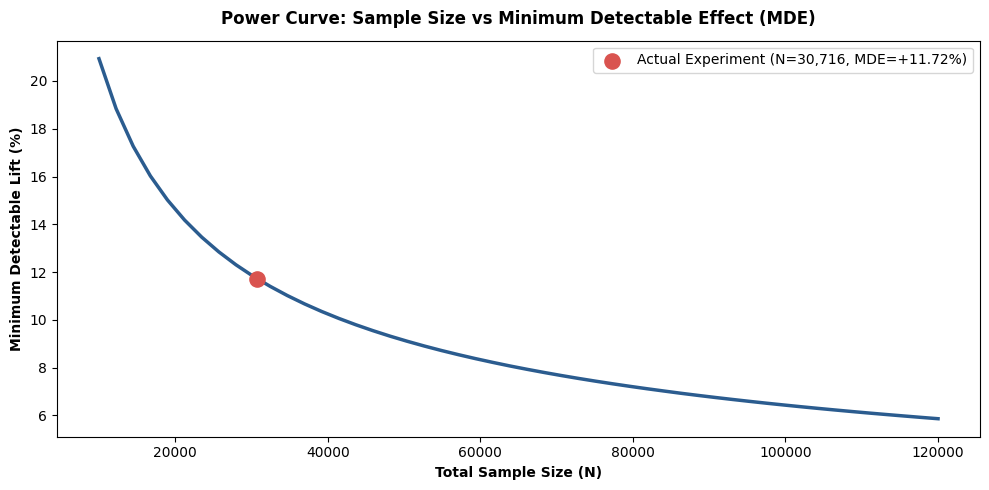

In [29]:
import statsmodels.stats.power as smp

# Power Curve
power_calc = smp.NormalIndPower()
p_baseline = df[df["variant"] == "control"]["converted"].mean()

sample_sizes = np.linspace(5000, 60000, 50)
mdes = []

for n in sample_sizes:
    h_mde = power_calc.solve_power(nobs1=n, power=0.80, alpha=0.05, ratio=1.0)
    p_mde = np.sin(h_mde / 2 + np.arcsin(np.sqrt(p_baseline))) ** 2
    rel_mde = ((p_mde - p_baseline) / p_baseline) * 100
    mdes.append(rel_mde)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sample_sizes * 2, mdes, color="#2b5c8f", linewidth=2.5)

# Actual experiment dot
ax.scatter(
    [len(df)],
    [11.72],
    color="#d9534f",
    s=120,
    zorder=5,
    label=f"Actual Experiment (N={len(df):,}, MDE=+11.72%)",
)

ax.set_title(
    "Power Curve: Sample Size vs Minimum Detectable Effect (MDE)",
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Total Sample Size (N)", fontweight="bold")
ax.set_ylabel("Minimum Detectable Lift (%)", fontweight="bold")
ax.legend(frameon=True)

plt.tight_layout()
plt.show()